In [1]:
import gc, os
import numpy as np, rasterio
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## Load the data
I load the packages and the two reference files. One is the EMODnet depth, which I reprojected onto the Sentinel 2 grid. The other tells me which 500 m block each pixel belongs to. I only keep pixels that are 0 to 15 m deep.

In [2]:
rng = np.random.default_rng(42)                       # one seed for every random draw
EPS = 1e-10
bands_folder = r"F:\data_water\processed\bands"
emodnet_file = r"F:\data_water\emodnet_reprojected.tif"
id_file      = r"F:\data_water\emodnet_block_id.tif"

with rasterio.open(emodnet_file) as s: depth = s.read(1).astype("float32")
with rasterio.open(id_file) as s:      gid   = s.read(1)

depth = np.where(depth == -32767.0, np.nan, depth)
gid   = np.where(gid < 0, -1, gid).astype("int32")    # -1 = no block (outside reference)
shallow = (depth < 0) & (depth >= -15) & (gid >= 0)   # 0-15 m, valid block

In [3]:
print(emodnet_file)
print(shallow.sum())

F:\data_water\emodnet_reprojected.tif
949704


## Is there a depth signal at all?
A check to see if the satellite values change with depth. I take the median over all scenes for every pixel and compare it with the depth. The green band gets darker as the water gets deeper (correlation about -0.6) and then stays flat after about 18 to 20 m. That is where the bottom can't be seen anymore.

In [4]:
from scipy.stats import spearmanr

idx = np.flatnonzero(shallow)                       # the 0-30 m pixels
stack = []
for fname in sorted(os.listdir(bands_folder)):      # go through all scenes
    if not fname.endswith(".tif"): continue
    with rasterio.open(os.path.join(bands_folder, fname)) as src:
        b3 = src.read(2).astype("float32").ravel()[idx] - 0.05   # green band, offset fix
    b3[b3 <= 0] = np.nan
    if np.isfinite(b3).mean() > 0.2:                # skip scenes that are mostly masked
        stack.append(np.log(b3))

med = np.nanmedian(np.vstack(stack), axis=0)        # median over all scenes, per pixel
d = -depth.ravel()[idx]                             # depth in metres (positive)
ok = np.isfinite(med)

print("scenes:", len(stack), "| pixels:", ok.sum())
print(spearmanr(d[ok], med[ok]))                    # the key number
bins = np.digitize(d[ok], np.arange(0, 32, 2))      # average per 2 m of depth
print([round(float(np.mean(med[ok][bins == k])), 3) for k in range(1, 16)])

C:\Users\haris\AppData\Local\Temp\ipykernel_8536\3835362334.py:13: RuntimeWarning: All-NaN slice encountered
  med = np.nanmedian(np.vstack(stack), axis=0)        # median over all scenes, per pixel


scenes: 54 | pixels: 946358
SignificanceResult(statistic=np.float64(-0.6110241356311987), pvalue=np.float64(0.0))
[-2.813, -3.037, -3.181, -3.349, -3.439, -3.536, -3.62, -3.684, nan, nan, nan, nan, nan, nan, nan]


c:\D\Harisankar\MY PERSONAL WORKS\sentinel2-water-quality-bathymetry\water_venv\Lib\site-packages\numpy\_core\fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\D\Harisankar\MY PERSONAL WORKS\sentinel2-water-quality-bathymetry\water_venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


## Collect pixels from all scenes
go through every scene and take the blue, green and red values of each shallow pixel, together with its depth and its block number, then ubtract 0.05 from the bands because my preprocessing missed a reflectance offset. Pixels with strange ratios are removed.

In [5]:
b02s, b03s, b04s, ys, gs = [], [], [], [], []
for fname in sorted(os.listdir(bands_folder)):
    if not fname.endswith(".tif"): continue
    try:
        with rasterio.open(os.path.join(bands_folder, fname)) as src:
            bands = src.read().astype("float32")
            bands[:3] -= 0.05                                    # remove net Sentinel-2 offset (see note)
            bands[:3][bands[:3] <= 0] = np.nan                   # log() needs positive reflectance
    except Exception as e:
        print(f"Error reading {fname}: {e}"); continue

    mask = shallow & ~np.isnan(bands[0]) & ~np.isnan(bands[1]) & ~np.isnan(bands[2])
    if not mask.any():
        del bands; gc.collect(); continue             # fully masked scene (clouds)

    b02, b03, b04 = bands[0][mask], bands[1][mask], bands[2][mask]
    ratio = np.log(b02 + EPS) / np.log(b03 + EPS)     # Stumpf ratio
    ok = np.isfinite(ratio) & (ratio > 0.7) & (ratio < 1.5)   # same outlier filter as before

    b02s.append(b02[ok]); b03s.append(b03[ok]); b04s.append(b04[ok])
    ys.append((-depth[mask])[ok])                     # positive depth in metres
    gs.append(gid[mask][ok])                          # block id of each pixel
    print(f"{fname}: {ok.sum():,} pixels")
    del bands; gc.collect()

b02, b03, b04 = map(np.concatenate, (b02s, b03s, b04s))
y, g = np.concatenate(ys), np.concatenate(gs)
del b02s, b03s, b04s, ys, gs; gc.collect()
print(f"\nTotal pixels: {len(y):,} | blocks: {len(np.unique(g)):,}")

Bands 20240224.tif: 216,726 pixels
Bands 20240310.tif: 269,577 pixels
Bands 20240330.tif: 568,745 pixels
Bands 20240404.tif: 881,480 pixels
Bands 20240414.tif: 854,191 pixels
Bands 20240524.tif: 822,410 pixels
Bands 20240608.tif: 938,390 pixels
Bands 20240613.tif: 938,199 pixels
Bands 20240623.tif: 927,286 pixels
Bands 20240628.tif: 934,811 pixels
Bands 20240708.tif: 935,173 pixels
Bands 20240718.tif: 934,144 pixels
Bands 20240723.tif: 939,800 pixels
Bands 20240728.tif: 931,541 pixels
Bands 20240802.tif: 868,838 pixels
Bands 20240812.tif: 933,151 pixels
Bands 20240817.tif: 939,904 pixels
Bands 20240822.tif: 936,130 pixels
Bands 20240827.tif: 793,239 pixels
Bands 20240926.tif: 228,515 pixels
Bands 20241125.tif: 171,913 pixels
Bands 20250109.tif: 170,926 pixels
Bands 20250310.tif: 326,519 pixels
Bands 20250514.tif: 883,154 pixels
Bands 20250519.tif: 932,594 pixels
Bands 20250524.tif: 935,525 pixels
Bands 20250603.tif: 904,878 pixels
Bands 20250608.tif: 885,638 pixels
Bands 20250613.tif: 

## Split into train and test
I split by blocks, not by single pixels. So every test block is a place the model has never seen. If splitted by pixels, neighbours would end up in both sets and the score would look too good. From each side we take a random sample: 1 million pixels for training and 2 million for testing. All models use the same samples.

In [6]:
# All pixels (any scene) of one 5x5-cell block go to train OR test, never both
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(np.zeros((len(y), 1), dtype="int8"), y, groups=g))

# Safety check: no block appears on both sides
assert len(np.intersect1d(np.unique(g[train_idx]), np.unique(g[test_idx]))) == 0
print(f"Train blocks: {len(np.unique(g[train_idx])):,} | Test blocks: {len(np.unique(g[test_idx])):,}")

tr = rng.choice(train_idx, 1_000_000, replace=False)  # training sample (same for all models)
te = rng.choice(test_idx, 2_000_000, replace=False)   # test sample (same for all models)

def bands_of(i):  return np.column_stack([b02[i], b03[i], b04[i]])
def stumpf_of(i): return (np.log(b02[i] + EPS) / np.log(b03[i] + EPS)).reshape(-1, 1)

y_tr, y_te = y[tr], y[te]
results = {}
def report(name, pred):
    # Score on the full 0-30 m range and on 0-15 m, where Sentinel-2 can see the bottom
    for rng_name, m in [("0-15 m", np.ones_like(y_te, bool)), ("0-8 m", y_te <= 8)]:
        r2 = r2_score(y_te[m], pred[m])
        rmse = np.sqrt(mean_squared_error(y_te[m], pred[m]))
        mae = mean_absolute_error(y_te[m], pred[m])
        results[(name, rng_name)] = (r2, rmse, mae)
        print(f"{name:<22} {rng_name}  R2={r2:.3f}  RMSE={rmse:.2f} m  MAE={mae:.2f} m")

Train blocks: 756 | Test blocks: 189


## Train the three models
First the Stumpf baseline (a simple line through the blue/green ratio). Then a random forest and a small neural network (MLP) on the three bands. All three are scored on the same test pixels.

In [7]:
# 1. Stumpf baseline: depth = m0 + m1 * ln(B02)/ln(B03)
lr = LinearRegression().fit(stumpf_of(tr), y_tr)
pred_lr = lr.predict(stumpf_of(te))
report("Stumpf LR", pred_lr)

# 2. Random Forest on the 3 bands
X_tr, X_te = bands_of(tr), bands_of(te)
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
pred_rf = rf.predict(X_te)
report("Random Forest", pred_rf)
print("RF importance (B02, B03, B04):", np.round(rf.feature_importances_, 3))

# 3. MLP 3 -> 64 -> 32 -> 16 -> 1, with scaling and early stopping
scaler = StandardScaler().fit(X_tr)
mlp = MLPRegressor(hidden_layer_sizes=(64, 32, 16), activation="relu", max_iter=200,
                   early_stopping=True, n_iter_no_change=10, random_state=42)
mlp.fit(scaler.transform(X_tr), y_tr)
pred_mlp = mlp.predict(scaler.transform(X_te))
report("MLP", pred_mlp)
print("MLP epochs run:", mlp.n_iter_)

Stumpf LR              0-15 m  R2=0.156  RMSE=3.68 m  MAE=3.02 m
Stumpf LR              0-8 m  R2=-2.982  RMSE=3.85 m  MAE=3.14 m
Random Forest          0-15 m  R2=0.400  RMSE=3.10 m  MAE=2.34 m
Random Forest          0-8 m  R2=-2.074  RMSE=3.38 m  MAE=2.44 m
RF importance (B02, B03, B04): [0.249 0.473 0.278]
MLP                    0-15 m  R2=0.463  RMSE=2.94 m  MAE=2.20 m
MLP                    0-8 m  R2=-1.930  RMSE=3.30 m  MAE=2.36 m
MLP epochs run: 29


## Results
Predicted depth against real depth for the three models, and a table with R², RMSE and MAE. The red line is a perfect prediction. The MLP is best, the Stumpf baseline is worst.

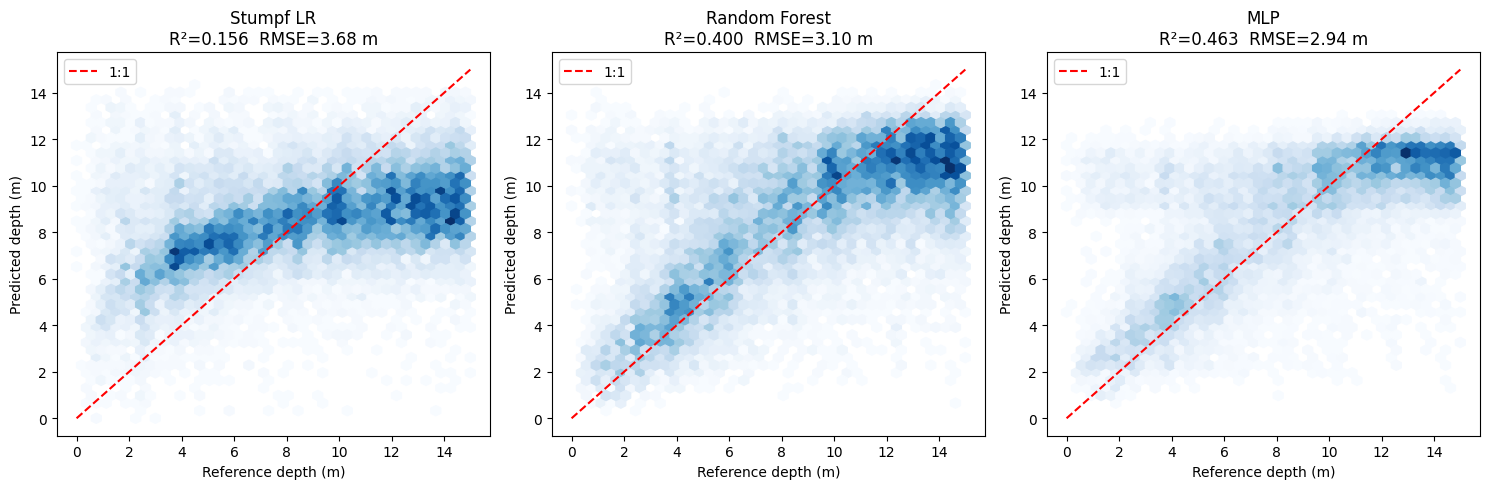


Model           Range         R2    RMSE     MAE
Stumpf LR       0-15 m     0.156    3.68    3.02
Stumpf LR       0-8 m     -2.982    3.85    3.14
Random Forest   0-15 m     0.400    3.10    2.34
Random Forest   0-8 m     -2.074    3.38    2.44
MLP             0-15 m     0.463    2.94    2.20
MLP             0-8 m     -1.930    3.30    2.36


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sel = rng.choice(len(y_te), 20_000, replace=False)    # plot a sample, not 2M points
for ax, (name, pred) in zip(axes, [("Stumpf LR", pred_lr), ("Random Forest", pred_rf), ("MLP", pred_mlp)]):
    ax.hexbin(y_te[sel], pred[sel], gridsize=40, extent=(0, 15, 0, 15), mincnt=1, cmap="Blues")
    ax.plot([0, 15], [0, 15], "r--", label="1:1")
    r2, rmse, _ = results[(name, "0-15 m")]
    ax.set(xlabel="Reference depth (m)", ylabel="Predicted depth (m)",
           title=f"{name}\nR²={r2:.3f}  RMSE={rmse:.2f} m")
    ax.legend()
plt.tight_layout(); plt.savefig("bathymetry_comparison.png", dpi=150); plt.show()

print(f"\n{'Model':<16}{'Range':<8}{'R2':>8}{'RMSE':>8}{'MAE':>8}")
for (name, rg), (r2, rmse, mae) in results.items():
    print(f"{name:<16}{rg:<8}{r2:>8.3f}{rmse:>8.2f}{mae:>8.2f}")

## Error by depth
Here I check where the models make mistakes. Bias is prediction minus real depth, so plus means too deep. The models are best between about 6 and 12 m. In the first 3 m they predict too deep, and below 12 m they predict too shallow because the satellite can't see the bottom anymore.

In [9]:
bins = np.arange(0, 18, 3)                              # 0-3, 3-6, ... 12-15 m
for name, pred in [("Random Forest", pred_rf), ("MLP", pred_mlp)]:
    print(name)
    for lo, hi in zip(bins[:-1], bins[1:]):
        k = (y_te >= lo) & (y_te < hi)
        e = pred[k] - y_te[k]
        print(f"  {lo:>2}-{hi:<2} m  n={k.sum():>8,}  bias={e.mean():+.2f} m  MAE={np.abs(e).mean():.2f} m  median|e|={np.median(np.abs(e)):.2f} m")

Random Forest
   0-3  m  n= 196,087  bias=+3.28 m  MAE=3.41 m  median|e|=1.87 m
   3-6  m  n= 429,360  bias=+1.72 m  MAE=2.25 m  median|e|=1.55 m
   6-9  m  n= 394,816  bias=+0.90 m  MAE=1.93 m  median|e|=1.65 m
   9-12 m  n= 448,196  bias=-0.57 m  MAE=1.54 m  median|e|=1.20 m
  12-15 m  n= 529,361  bias=-2.96 m  MAE=2.99 m  median|e|=2.72 m
MLP
   0-3  m  n= 196,087  bias=+3.29 m  MAE=3.37 m  median|e|=1.70 m
   3-6  m  n= 429,360  bias=+1.70 m  MAE=2.16 m  median|e|=1.41 m
   6-9  m  n= 394,816  bias=+0.91 m  MAE=1.82 m  median|e|=1.59 m
   9-12 m  n= 448,196  bias=-0.52 m  MAE=1.28 m  median|e|=0.96 m
  12-15 m  n= 529,361  bias=-2.86 m  MAE=2.87 m  median|e|=2.71 m


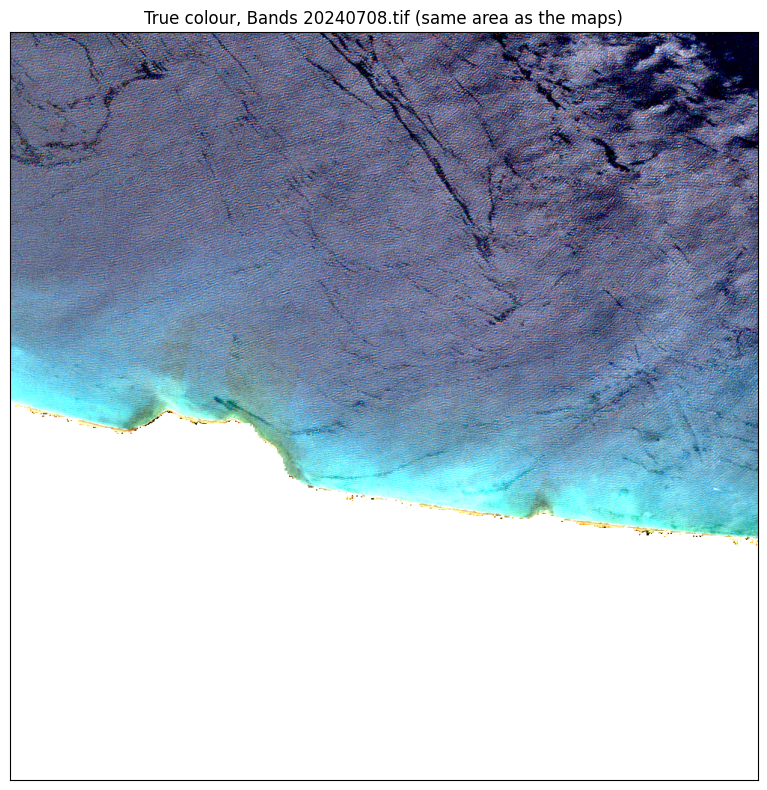

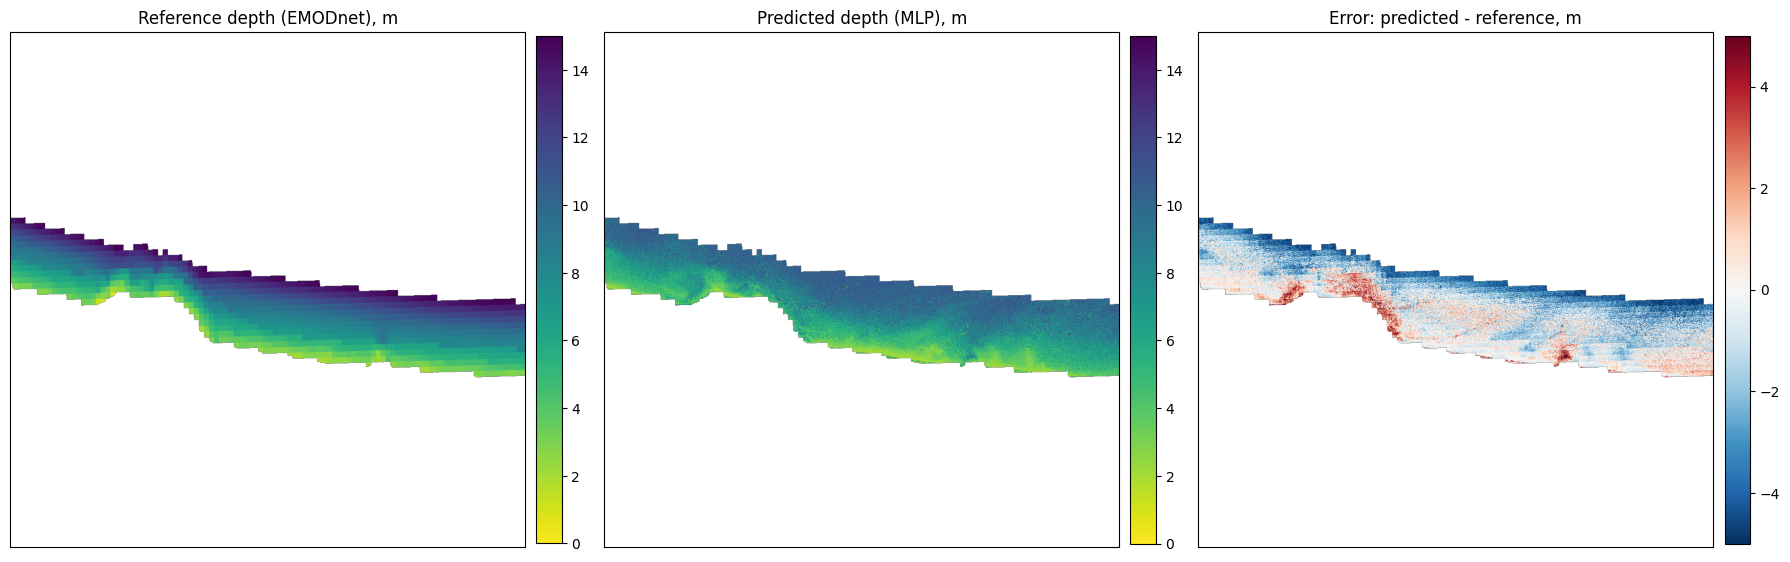

In [10]:
from matplotlib.colors import Normalize

# ---- 1) predict depth for every 0-15 m pixel of one clear scene
fn = "Bands 20240708.tif"                                   # a clear summer scene
with rasterio.open(os.path.join(bands_folder, fn)) as s:
    b = s.read([1, 2, 3]).astype("float32") - 0.05          # B02, B03, B04 (+ offset fix)

ONLY_TEST_BLOCKS = False                                    # True = show only blocks the model never saw
valid = shallow & np.all(b > 0, axis=0)
if ONLY_TEST_BLOCKS:
    valid &= np.isin(gid, np.unique(g[test_idx]))           # held-out blocks only

X = np.column_stack([b[0][valid], b[1][valid], b[2][valid]])
pred = np.full(depth.shape, np.nan, "float32")
pred[valid] = np.clip(mlp.predict(scaler.transform(X)), 0, 15)
ref = np.where(valid, -depth, np.nan)                       # reference depth, same pixels
err = pred - ref

# ---- 2) crop around the area with the most shallow pixels
H, W = valid.shape; bs = 250
cnt = valid[:H//bs*bs, :W//bs*bs].reshape(H//bs, bs, W//bs, bs).sum(axis=(1, 3))
i, j = np.unravel_index(cnt.argmax(), cnt.shape)
r0, c0 = max(i*bs - 375, 0), max(j*bs - 375, 0)
sl = (slice(r0, r0 + 1000), slice(c0, c0 + 1000))           # 10 km x 10 km window

crop = b[:, sl[0], sl[1]]                                  # B02, B03, B04 over the same crop
rgb = np.stack([crop[2], crop[1], crop[0]], axis=-1)       # R = B04, G = B03, B = B02

lo, hi = np.nanpercentile(rgb, 2), np.nanpercentile(rgb, 98)
rgb = np.clip((rgb - lo) / (hi - lo), 0, 1) ** 0.8         # contrast stretch + slight brightening
rgb = np.where(np.isnan(rgb), 1.0, rgb)                    # masked pixels (land/clouds) shown white

plt.figure(figsize=(8, 8)); plt.imshow(rgb)
plt.title(f"True colour, {fn} (same area as the maps)"); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.savefig("scene_rgb.png", dpi=200); plt.show()

# ---- 3) three panels: reference, prediction, error
fig, ax = plt.subplots(1, 3, figsize=(18, 6.5))
for a, arr, title, cmap, norm in [
        (ax[0], ref, "Reference depth (EMODnet), m",  "viridis_r", Normalize(0, 15)),
        (ax[1], pred, "Predicted depth (MLP), m",     "viridis_r", Normalize(0, 15)),
        (ax[2], err,  "Error: predicted - reference, m", "RdBu_r", Normalize(-5, 5))]:
    im = a.imshow(arr[sl], cmap=cmap, norm=norm)
    a.set_title(title); a.set_xticks([]); a.set_yticks([])
    plt.colorbar(im, ax=a, fraction=0.046, pad=0.02)
plt.tight_layout()
plt.savefig("bathymetry_map.png", dpi=200); plt.show()

In [11]:
# ---- Export the depth maps for the website ( with ONLY_TEST_BLOCKS = False)
import json
from rasterio.windows import Window, bounds as win_bounds, transform as win_transform
from rasterio.warp import calculate_default_transform, reproject, transform_bounds, Resampling
from rasterio.transform import array_bounds
from PIL import Image

SITE  = r"C:\D\Harisankar\MY PERSONAL WORKS\sentinel2-water-quality-bathymetry\docs"   # folder with index.html
RES_M = 20                                                  # web map pixel size on the ground (m)
out = os.path.join(SITE, "data"); os.makedirs(out, exist_ok=True)

with rasterio.open(emodnet_file) as s: src_tr, src_crs = s.transform, s.crs

# window around all predicted pixels, with a 500 m margin
rr, cc = np.where(np.isfinite(pred))
r_a, r_b = max(rr.min() - 50, 0), min(rr.max() + 50, pred.shape[0])
c_a, c_b = max(cc.min() - 50, 0), min(cc.max() + 50, pred.shape[1])
win = Window(c_a, r_a, c_b - c_a, r_b - r_a)
w_tr, w_bounds = win_transform(win, src_tr), win_bounds(win, src_tr)

# target grid in Web Mercator (what Leaflet uses); RES_M on the ground at this latitude
lat = np.mean(transform_bounds(src_crs, "EPSG:4326", *w_bounds)[1::2])
dst_tr, W, H = calculate_default_transform(src_crs, "EPSG:3857", win.width, win.height, *w_bounds,
                                          resolution=RES_M / np.cos(np.radians(lat)))

def to_web(a):                                              # crop + reproject one layer, NaN stays NaN
    dst = np.full((H, W), np.nan, "float32")
    reproject(a[r_a:r_b, c_a:c_b].astype("float32"), dst, src_transform=w_tr, src_crs=src_crs,
              dst_transform=dst_tr, dst_crs="EPSG:3857", src_nodata=np.nan, dst_nodata=np.nan,
              resampling=Resampling.nearest)
    return dst

def colour(a, lo, hi, ramp):                                # value -> RGBA along a colour ramp
    stops = np.array([[int(h[i:i + 2], 16) for i in (1, 3, 5)] for h in ramp], "float32")
    t = np.clip((np.nan_to_num(a, nan=lo) - lo) / (hi - lo), 0, 1) * (len(ramp) - 1)
    i = np.minimum(t.astype(int), len(ramp) - 2); f = (t - i)[..., None]
    rgb = stops[i] * (1 - f) + stops[i + 1] * f
    alpha = np.where(np.isfinite(a), 255, 0)[..., None]
    return Image.fromarray(np.concatenate([rgb, alpha], -1).astype("uint8"), "RGBA")

DEPTH = ["#d6ecfa", "#9ec5f4", "#5598e7", "#2a6bc0", "#1a4a8a", "#0e2c55"]       # shallow -> deep
DIV   = ["#9ec5f4", "#5598e7", "#2a5f9e", "#3b3f40", "#9e3a3a", "#e34948", "#f4a3a3"]  # too shallow -> too deep
test  = np.isin(gid, np.unique(g[test_idx]))               # blocks the model never saw

layers = [  # id, array, range, ramp, kind, button label, legend title, legend subtitle
    ("mlp", pred, (0, 15), DEPTH, "sequential", "Predicted depth", "Predicted depth (neural network)", "Scene of 8 July 2024"),
    ("ref", ref, (0, 15), DEPTH, "sequential", "EMODnet depth", "Reference depth (EMODnet DTM 2024)", "Cells of about 115 m"),
    ("err", err, (-5, 5), DIV, "diverging", "Error", "Predicted minus reference", "All blocks"),
    ("err_test", np.where(test, err, np.nan), (-5, 5), DIV, "diverging", "Error, test blocks",
     "Predicted minus reference", "Held-out blocks only"),
]
meta = {"layers": []}
for lid, arr, rng_, ramp, kind, label, title, sub in layers:
    colour(to_web(arr), *rng_, ramp).save(os.path.join(out, f"{lid}.webp"), quality=85, method=6)
    meta["layers"].append({"id": lid, "file": f"{lid}.webp", "range": rng_, "ramp": ramp, "kind": kind,
                           "label": label, "title": title, "sub": sub})

# Leaflet wants [[south, west], [north, east]]
w, s_, e, n = transform_bounds("EPSG:3857", "EPSG:4326", *array_bounds(H, W, dst_tr))
meta["bounds"] = [[s_, w], [n, e]]
w, s_, e, n = transform_bounds(src_crs, "EPSG:4326", *win_bounds(Window(c0, r0, 1000, 1000), src_tr))
meta["focus"] = [[s_, w], [n, e]]                          # the 10 km crop of the figures
json.dump(meta, open(os.path.join(out, "meta.json"), "w"), indent=1)
print(f"{W} x {H} px, files:", {f: f"{os.path.getsize(os.path.join(out, f)) / 1e6:.1f} MB" for f in os.listdir(out)})

4295 x 4088 px, files: {'err.webp': '0.2 MB', 'err_test.webp': '0.1 MB', 'meta.json': '0.0 MB', 'mlp.webp': '0.1 MB', 'ref.webp': '0.1 MB'}
